# 📈 프로젝트 관리자 집단 사이의 소통 — 데이터 분석 빈칸 실습

두 부서의 프로젝트 관리자들이 서로 소통하며 일을 진행하는 모습을 흉내 낸 연습용 자료예요. 서로 믿고 자주 이야기하면 일이 순조롭지만, 소통이 막히면 일정이 밀려요. 소통과 신뢰가 일의 속도를 얼마나 바꾸는지 알아보면 재미있어요.

**핵심 속성(변수)**
- **틱마다 소통 횟수**(회) — 한 차례마다 서로 이야기하는 횟수예요. 클수록 자주 소통해요.
- **두 집단 사이 신뢰**(점) — 두 부서가 서로 믿는 정도예요. 클수록 협력이 잘돼요.
- **소통 가능한 범위**(칸) — 이야기를 나눌 수 있는 거리예요. 클수록 더 많은 사람과 소통해요.
- **관리자 수**(명) — 프로젝트 관리자의 수예요. 클수록 조율할 사람이 많아요.
- **결과** — 프로젝트가 계획보다 늦어진 날수(일)예요.

**기타 속성** — 결과와 관련이 있을까? 상관을 보고 넣을지 뺄지 **내가 골라요**.
- 보고서 표지 색 번호(번) — 보고서 표지 색에 붙인 번호예요.
- 측정 장소 번호(번) — 자료를 기록한 장소에 붙인 번호예요.
- 관찰한 요일 번호(번) — 자료를 모은 날이 무슨 요일인지 숫자로 나타낸 값이에요.
- 회의 참석률(%) — 정해진 회의에 실제로 오는 사람의 비율이에요.

> ⚠️ 연습용 합성 데이터(실제 측정 아님)

### 오늘 할 일 (약 30분) — 수업에서 배운 순서 그대로
1. 불러오기 → 2. 결측치 → 3. 이상치(IQR) → 4. 요약 → 5. 그래프 → 6. 상관으로 속성 고르기 → 7. train_test_split → 8. 회귀 모델 → 9. 내 생각

`______` 빈칸에 알맞은 **함수 이름이나 숫자**를 넣고 ▶ 실행해요. 막히면 **오픈북** — 클래스룸에 올린 그간의 실습 파일(Pandas 문법·결측치·이상치·예측·분류)을 펴 보고 같은 코드를 찾아 써요. 단계마다 📖 에 어느 파일 몇 번 숙제인지 적어 두었어요.

In [ ]:
# 0. 준비 — 그대로 실행해요 (한글 그래프 글꼴)
!pip -q install koreanize-matplotlib
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib

## 1. 데이터 불러오기
CSV 파일을 표(DataFrame)로 읽어요. 함수 이름은 **읽다(read) + csv**.

📖 **오픈북** — 「#16 펭귄-분류」 숙제01 `pd.read_csv(url)` · 「Pandas 문법-(A~E)」 `df.head()`

In [ ]:
URL = "https://baehwa-ai-2026.web.app/dataproject/csv/c776_n.csv"
df = pd.______(URL)      # 힌트: CSV 를 읽는 함수
print(df.shape)          # (행 수, 열 수)
df.______()              # 힌트: 앞 5줄만 보기

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)


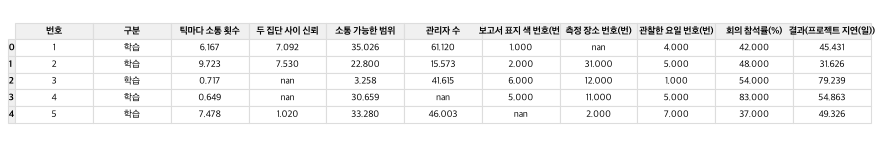

## 2. 결측치(빈칸) 처리
빈칸이 몇 개인지 세고, 빈칸이 있는 줄을 지워요. (평균으로 채우는 `fillna(df[열].mean())` 도 배웠죠 — 해 보고 싶으면 바꿔 봐요.)

📖 **오픈북** — 「#16 펭귄-분류」 숙제05 `df.isnull().sum()` · 숙제06 `df.dropna(axis=0)` · 「#12 결측치(seoultemp)」

In [ ]:
print(df.______().sum())   # 힌트: 빈칸인지 True/False — 열마다 개수
df = df.______()            # 힌트: 빈칸 있는 줄 지우기
print('빈칸 지운 뒤', df.shape)

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)

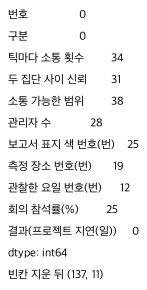

## 3. 이상치(IQR) 처리
값을 작은 것부터 줄 세웠을 때 4분의 1 지점이 Q1, 4분의 3 지점이 Q3 예요. 둘 사이 거리를 IQR 이라고 해요(가운데 절반이 퍼진 폭). **Q1 − 1.5×IQR 보다 작거나 Q3 + 1.5×IQR 보다 크면 이상치**로 보고 지워요.

단, 1~4 등급이나 「거의 0인 횟수」처럼 **값 종류가 몇 개뿐인 열은 건너뛰어요** — 그런 열의 드문 값은 이상치가 아니라 정상이에요.

📖 **오픈북** — 「#14 Iris 데이터 전처리(이상치)」 숙제14 `quantile(0.25)` · 숙제15 `Q3 + 1.5 * IQR`

In [ ]:
for col in ["틱마다 소통 횟수", "두 집단 사이 신뢰", "소통 가능한 범위", "관리자 수"]:
    q1 = df[col].______(0.25)        # 힌트: 분위수
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    if iqr == 0 or df[col].nunique() <= 5: continue      # 값 종류가 적은 열은 건너뛰기
    하한 = q1 - 1.5 * iqr
    상한 = q3 + ______ * iqr          # 힌트: 몇 배?
    df = df[(df[col] >= 하한) & (df[col] <= 상한)]
print('이상치 지운 뒤', df.shape)

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)



## 4. 요약 통계
평균·최솟값·최댓값을 한 번에 봐요. 이상치를 지운 뒤 값이 그럴듯해졌나요?

📖 **오픈북** — 「#14 Iris 데이터 전처리(이상치)」 숙제03 `df.describe()`

In [ ]:
df.______()               # 힌트: 숫자 열 요약

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)

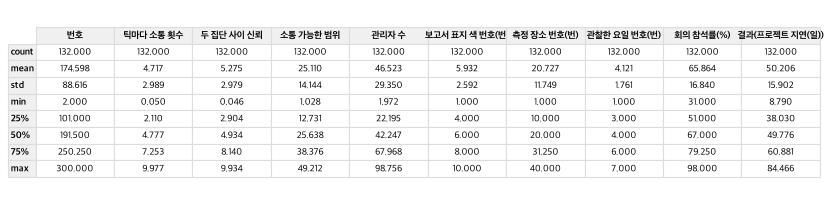

## 5. 관계 그래프
`틱마다 소통 횟수` 이(가) 바뀔 때 결과는 어떻게 바뀌나요? 점 그래프(산점도)로 봐요.

📖 **오픈북** — 「목둘레 허리둘레-예측」 숙제09 `plt.scatter(X_test, y_test)`

In [ ]:
plt.______(df["틱마다 소통 횟수"], df["결과(프로젝트 지연(일))"])   # 힌트: 점 그래프(산점도)
plt.xlabel("틱마다 소통 횟수"); plt.ylabel("결과(프로젝트 지연(일))")
plt.show()

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)

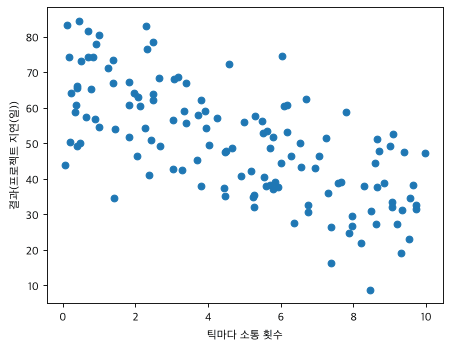

## 6. 상관으로 속성 고르기
결과와의 상관계수예요. 1이나 −1에 가까울수록 관련이 크고, 0 근처면 거의 관련 없어요. **기타 속성은 넣을까요, 뺄까요?**

⚠ 상관이 크다고 「원인」이라는 뜻은 아니에요. 그리고 상관계수는 **직선 관계**만 재요 — 곡선 관계는 0 근처로 나올 수 있어요.

📖 **오픈북** — 「#14 Iris 데이터 전처리(이상치)」 숙제19 `df.corr(numeric_only=True)`

In [ ]:
df.______(numeric_only=True)["결과(프로젝트 지연(일))"].sort_values()   # 힌트: 상관계수

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)

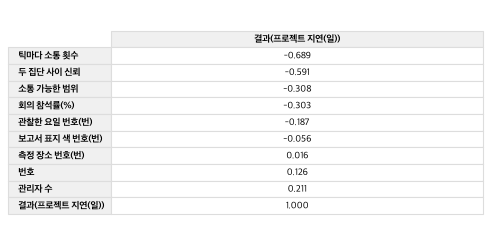

## 7. 학습용 / 시험용 나누기 — train_test_split
수업에서 배운 그대로 30% 를 시험용으로 떼어 놓아요. X 에는 6번에서 고른 속성을 넣어요.

📖 **오픈북** — 「예측-전복나이」 숙제03 · 「#16 펭귄-분류」 숙제07 `train_test_split(X, y, test_size=0.3, random_state=42)`

In [ ]:
from sklearn.model_selection import train_test_split
X = df[["틱마다 소통 횟수", "두 집단 사이 신뢰", "소통 가능한 범위", "관리자 수"]]   # ← 6번을 보고 속성을 넣거나 빼 봐요
y = df["결과(프로젝트 지연(일))"]
X_train, X_test, y_train, y_test = ______(X, y, test_size=0.3, random_state=42)   # 힌트: 나누는 함수
print(len(X_train), len(X_test))

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)



## 8. 예측 모델 만들기 (선형 회귀)
학습용으로 맞추고(fit), 시험용으로 점수(score)를 봐요. 1 에 가까울수록 잘 맞아요.

점수가 0 근처거나 **0보다 작으면** 「그냥 평균으로 찍는 것보다도 못하다」는 뜻이에요 — 고른 속성이 결과를 잘 설명하지 못하거나, 관계가 직선이 아닐 수 있어요. 틀린 게 아니라 **발견**이에요. 보고서 「1-5. 한계」에 적어요.

📖 **오픈북** — 「예측-전복나이」 숙제04 `model.fit(X_train, y_train)` · `model.score(X_test, y_test)`

In [ ]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.______(X_train, y_train)                    # 힌트: 학습시키기
print('시험 점수', model.______(X_test, y_test))   # 힌트: 점수 매기기

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)



## 9. (더 해 보기) 분류형 데이터
같은 모형의 분류형 데이터예요. 결과 `결과(지연이 큰지 여부)` 별로 속성 평균이 어떻게 다른지 묶어서 봐요.

📖 **오픈북** — 「#14 Iris 데이터 전처리(이상치)」 숙제04 `df.groupby('종류')`

In [ ]:
dc = pd.read_csv("https://baehwa-ai-2026.web.app/dataproject/csv/c776_c.csv").dropna()
# 이상치가 섞이면 평균이 튀어요 — 3번에서 배운 IQR 거르기를 여기서도 해요
for col in ["틱마다 소통 횟수", "두 집단 사이 신뢰", "소통 가능한 범위", "관리자 수"]:
    q1, q3 = dc[col].quantile(0.25), dc[col].quantile(0.75)
    if q3 == q1 or dc[col].nunique() <= 5: continue      # 값 종류가 적은 열은 건너뛰기
    dc = dc[(dc[col] >= q1 - 1.5 * (q3 - q1)) & (dc[col] <= q3 + 1.5 * (q3 - q1))]
dc.______("결과(지연이 큰지 여부)").mean(numeric_only=True)   # 힌트: 묶어서(group) 보기

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)

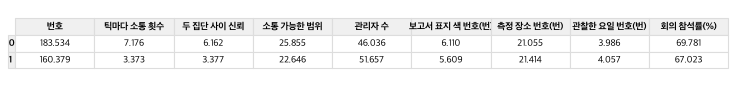

## 10. 내 생각 쓰기
아래를 보고서 「1-4. 그래프 설명」·「1-5. 한계」 칸에 옮겨 써요.
- 그래프에서 읽은 숫자 하나와 그 뜻
- 가장 관련이 큰 속성과 그 이유 · 기타 속성을 넣었는지 뺐는지와 그 이유
- 이 결과를 그대로 믿기 어려운 이유 (합성 데이터·지운 줄·빠진 변수 등)